# Two-stage fall model (accel trigger + learned check), with vs without gyro, tested on WEDA-FALL

**Three questions:**
1. **Combine both ideas:** a cheap **accel trigger** (peak > 2.5 g) finds candidate moments, then a **learned model** (random forest using accel + gyro) decides if it was really a fall. This is the "accel says fall, gyro confirms" idea, but the confirmation is learned from data instead of one hand-picked gyro threshold.
2. **Does the gyro help?** Train the same model with and without gyro features. Removing one ingredient to see its value is called an **ablation**.
3. **Does it work on a different watch and different people?** Train on FallAllD only, then test on **WEDA-FALL** (Fitbit watch, includes older adults' daily activities). This is the honest preview of how it will behave on our own MPU-6050.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve, confusion_matrix

import fad_utils as fu

pd.set_option('display.width', 170)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
TEST_SUBJECTS = [1, 11, 12]       # FallAllD people held out, same as the earlier notebooks
TRIGGER_G = 2.5
SEED = 42

## Step 1. FallAllD wrist data (same preparation as before)
Accel in g, gyro in deg/s, 50 Hz, 2.5 s windows. We also make a second copy with the accelerometer **cut off at 4 g**, because WEDA-FALL's watch cannot measure above 4 g. To compare fairly, the model must learn on data that looks the same.

In [2]:
fad_trials, ACC, GYR = fu.load_device()
fad_win, fa, fg = fu.make_windows(ACC, GYR, fad_trials)[:3]
X_fad = fu.make_features(fa, fg)                         # full range
X_fad4 = fu.make_features(fu.clip_accel(fa, 4.0), fg)    # cut off at 4 g, like WEDA
y_fad = fad_win.y.to_numpy(); g_fad = fad_win.subject.to_numpy()
SETS = fu.feature_sets(X_fad.columns)
print(f'FallAllD: {len(fad_win):,} windows, {y_fad.sum():,} fall windows, {fad_win.subject.nunique()} people')
print('feature sets:', {k: len(v) for k, v in SETS.items()})

FallAllD: 37,725 windows, 1,045 fall windows, 13 people
feature sets: {'accel only (all axes)': 23, 'accel only (magnitude)': 8, 'accel + gyro (magnitude)': 14, 'accel + gyro (all axes)': 44}


## Step 2. The two-stage model

```
window -> [Stage 1] peak accel > 2.5 g ?  --no-->  not a fall
                         | yes
                         v
          [Stage 2] random forest: fall probability >= threshold ?  --> FALL / not a fall
```
- Stage 2 is trained **only on windows that passed Stage 1**, so it specialises in the hard question: "this was a big spike, was it a fall or something else?"
- The threshold is chosen with grouped cross-validation on the training people, keeping overall fall recall >= 90% (missing falls is worse than a false alarm).

In [3]:
def fit_two_stage(X, y, groups, cols, min_recall=0.90):
    trig = X['am_max'].to_numpy() > TRIGGER_G
    Xs, ys, gs = X.loc[trig, cols], y[trig], groups[trig]
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)
    p = cross_val_predict(rf, Xs, ys, groups=gs, cv=GroupKFold(5), method='predict_proba')[:, 1]
    need = min(min_recall * y.sum() / max(ys.sum(), 1), 1.0)        # recall needed inside stage 2 to reach 90% overall
    prec, rec, thr = precision_recall_curve(ys, p)
    ok = rec[:-1] >= need
    thr_ = float(thr[ok][-1]) if ok.any() else float(thr[0])
    rf.fit(Xs, ys)
    return {'rf': rf, 'thr': thr_, 'cols': cols}

def predict_two_stage(m, X):
    out = np.zeros(len(X), dtype=int)
    trig = X['am_max'].to_numpy() > TRIGGER_G
    if trig.any():
        out[trig] = (m['rf'].predict_proba(X.loc[trig, m['cols']])[:, 1] >= m['thr']).astype(int)
    return out

def scores(name, y, pred, meta):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    hours = (y == 0).sum() * fu.HOP / fu.FS_OUT / 3600
    caught = meta.assign(pred=pred, y=y)[y == 1].groupby('rec').pred.max()
    return {'model': name, 'recall': tp / max(tp + fn, 1) if (tp + fn) else np.nan, 'precision': tp / max(tp + fp, 1),
            'false alarms / hour': fp / hours, 'fall recordings caught': f'{int(caught.sum())}/{len(caught)}' if len(caught) else '-'}

### 2a. Results on the 3 held-out FallAllD people
Rows: the plain accel rule, a one-stage forest (all windows, as in the first notebook), and the two-stage model with each feature set.

In [4]:
is_test = np.isin(g_fad, TEST_SUBJECTS)
assert set(g_fad[is_test]).isdisjoint(set(g_fad[~is_test]))
tr, te = ~is_test, is_test
te_meta = fad_win[te].reset_index(drop=True)

rows = [scores(f'rule: peak > {TRIGGER_G} g', y_fad[te], (X_fad.am_max[te] > TRIGGER_G).astype(int).to_numpy(), te_meta)]
one = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)
p = cross_val_predict(one, X_fad[tr], y_fad[tr], groups=g_fad[tr], cv=GroupKFold(5), method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_fad[tr], p); one_thr = float(thr[rec[:-1] >= 0.90][-1])
one.fit(X_fad[tr], y_fad[tr])
rows.append(scores('one-stage forest (all features)', y_fad[te], (one.predict_proba(X_fad[te])[:, 1] >= one_thr).astype(int), te_meta))

fad_models = {}
for name, cols in SETS.items():
    fad_models[name] = fit_two_stage(X_fad[tr], y_fad[tr], g_fad[tr], cols)
    rows.append(scores(f'two-stage: {name}', y_fad[te], predict_two_stage(fad_models[name], X_fad[te]), te_meta))
fad_results = pd.DataFrame(rows).set_index('model')
print(f'FallAllD test people {TEST_SUBJECTS}')
fad_results

FallAllD test people [1, 11, 12]


,recall,precision,false alarms / hour,fall recordings caught
model,,,,
rule: peak > 2.5 g,1.000,0.142,312.940,73/73
one-stage forest (all features),0.979,0.627,30.227,73/73
two-stage: accel only (all axes),0.973,0.566,38.762,73/73
two-stage: accel only (magnitude),0.945,0.366,84.992,73/73
two-stage: accel + gyro (magnitude),0.945,0.390,76.812,72/73
two-stage: accel + gyro (all axes),0.966,0.610,32.005,73/73


## Step 3. Prepare WEDA-FALL to look like the training data

`fu.load_weda()` fixes the problems found in the audit: it sorts the bursty timestamps, drops repeated times, and **interpolates accel and gyro onto one even 50 Hz grid**, then converts units.

**The gyro unit is not documented, so we test it** with the same physics check as the gyro notebook. When the watch turns between two still poses, the accelerometer shows how far gravity turned, and adding up the gyro readings must give the same angle.

In [5]:
def still_runs(mask, minlen):
    out, i, n = [], 0, len(mask)
    while i < n:
        if mask[i]:
            j = i
            while j < n and mask[j]: j += 1
            if j - i >= minlen: out.append((i, j))
            i = j
        else:
            i += 1
    return out

def angle(u, v):
    return np.degrees(np.arccos(np.clip(np.dot(u, v) / np.linalg.norm(u) / np.linalg.norm(v), -1, 1)))

def rotate_gravity(g, w_rad, fs=fu.FS_OUT, sign=-1):
    for th in w_rad / fs:
        a = np.linalg.norm(th)
        if a > 0:
            k = th / a; c, s = np.cos(sign * a), np.sin(sign * a)
            g = g * c + np.cross(k, g) * s + k * np.dot(k, g) * (1 - c)
    return g

weda_trials, W_ACC, W_GYR = fu.load_weda()
raw_units = 1 / fu.WEDA_GYRO_DPS_PER_UNIT                  # undo the conversion to test the raw numbers
pairs = []
for A, G in zip(W_ACC, W_GYR):
    m = np.linalg.norm(A, axis=1)
    still = (pd.Series(m).rolling(25, center=True).std().to_numpy() < 0.02) & (np.abs(m - 1) < 0.1)
    R = still_runs(still, 15)
    for (a0, a1), (b0, b1) in zip(R, R[1:]):
        g1, g2 = A[max(a1 - 8, a0):a1].mean(0), A[b0:b0 + 8].mean(0)
        if (b0 - a1) / fu.FS_OUT <= 4 and angle(g1, g2) > 30:
            pairs.append((g1, g2, G[a1:b0] * raw_units, angle(g1, g2))); break
    if len(pairs) >= 150: break

rows = []
for unit, to_rad in [('raw numbers are deg/s', np.pi / 180), ('raw numbers are rad/s', 1.0)]:
    err = [angle(rotate_gravity(g1 / np.linalg.norm(g1), w * to_rad), g2) for g1, g2, w, _ in pairs]
    path = [np.linalg.norm(w, axis=1).sum() * to_rad / fu.FS_OUT / np.radians(ang) for _, _, w, ang in pairs]
    rows.append({'hypothesis': unit, 'median error (deg)': np.median(err), 'impossible cases': np.mean(np.array(path) < 1)})
print(f'{len(pairs)} still->turn->still moments, median turn {np.median([q[3] for q in pairs]):.0f} deg')
pd.DataFrame(rows).set_index('hypothesis')

150 still->turn->still moments, median turn 61 deg


,median error (deg),impossible cases
hypothesis,,
raw numbers are deg/s,59.647,1.000
raw numbers are rad/s,10.037,0.013


**Result:** WEDA's gyro is in **rad/s**. That is the only reading consistent with physics, so the loader multiplies by 57.3 to get deg/s. Its rotation sign is also the *opposite* of FallAllD's: the two watches define their axes differently. This is a good reason to expect the **magnitude-only** features (which ignore direction) to transfer better than per-axis ones.

Now cut WEDA into the same windows. A fall window is the one containing the biggest spike **inside the hand-annotated fall interval**.

WEDA: 969 recordings, 8,412 windows, 702 fall windows (all from young people)
median |accel| 1.003 g | gyro in calm windows 2.7 deg/s
windows by group: {'older': 1139, 'young': 7273}


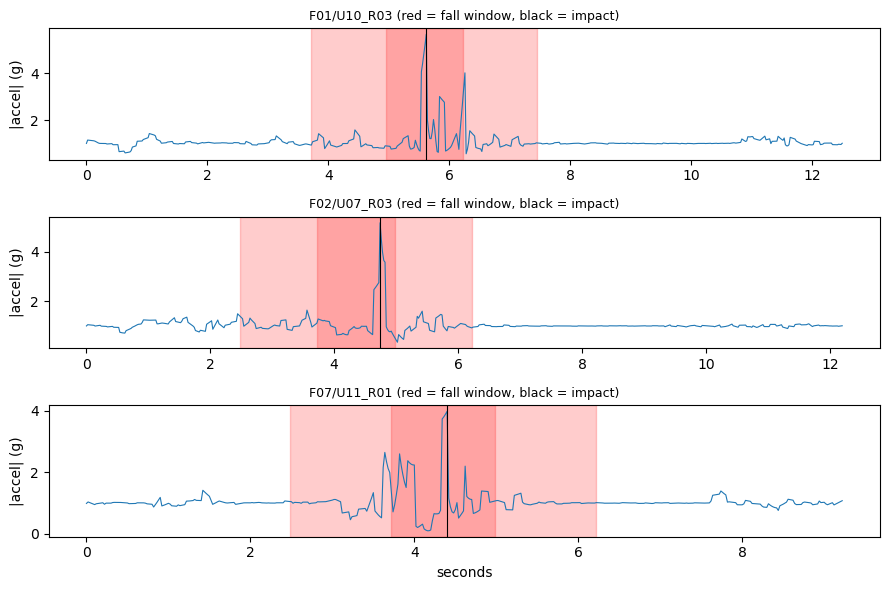

In [6]:
weda_win, wa, wg = fu.windows_from_list(W_ACC, W_GYR, weda_trials)
X_weda = fu.make_features(wa, wg)
y_weda = weda_win.y.to_numpy()
calm = X_weda.am_std < 0.01
print(f'WEDA: {len(weda_trials)} recordings, {len(weda_win):,} windows, {y_weda.sum()} fall windows (all from young people)')
print(f'median |accel| {np.median(np.linalg.norm(np.concatenate(W_ACC), axis=1)):.3f} g | gyro in calm windows {X_weda.gm_mean[calm].median():.1f} deg/s')
print('windows by group:', weda_win.groupby('group').size().to_dict())

pick = np.random.default_rng(3).choice(np.where(weda_trials.is_fall)[0], 3, replace=False)
fig, axes = plt.subplots(3, 1, figsize=(9, 6))
for ax, r in zip(axes, pick):
    A = W_ACC[r]; t = np.arange(len(A)) / fu.FS_OUT; key = weda_trials.key[r]
    ax.plot(t, np.linalg.norm(A, axis=1), lw=0.8)
    for s in weda_win[(weda_win.rec == r) & (weda_win.y == 1)].start:
        ax.axvspan(s / fu.FS_OUT, (s + fu.WIN) / fu.FS_OUT, color='red', alpha=0.2)
    ax.axvline(weda_trials.impact[r] / fu.FS_OUT, color='k', lw=0.8)
    ax.set_title(f'{key} (red = fall window, black = impact)', fontsize=9); ax.set_ylabel('|accel| (g)')
axes[-1].set_xlabel('seconds'); plt.tight_layout(); plt.show()

## Step 4. Train on FallAllD, test on WEDA-FALL

Train on **all 13 FallAllD people** (WEDA is never used for training or tuning), then test once on all of WEDA. We train two versions: normal, and with FallAllD's accel **cut off at 4 g** to match WEDA's watch.

Columns:
- **young: recall** and **recordings caught**: how many falls it catches (only young people fell).
- **young / older: false alarms per hour**: how often it cries wolf during daily activities. The **older** column matters most for SilverGuard.

In [7]:
def weda_scores(name, pred):
    out = {'model': name}
    for grp in ('young', 'older'):
        m = (weda_win.group == grp).to_numpy()
        s = scores(name, y_weda[m], pred[m], weda_win[m].reset_index(drop=True))
        if grp == 'young':
            out['young: recall'], out['young: recordings caught'] = s['recall'], s['fall recordings caught']
        out[f'{grp}: false alarms / hour'] = s['false alarms / hour']
    return out

rows = [weda_scores(f'rule: peak > {TRIGGER_G} g', (X_weda.am_max > TRIGGER_G).astype(int).to_numpy())]
cross_models = {}
for clip_name, Xtrain in [('normal', X_fad), ('trained at 4 g', X_fad4)]:
    for name, cols in SETS.items():
        m = fit_two_stage(Xtrain, y_fad, g_fad, cols)
        cross_models[(clip_name, name)] = m
        rows.append(weda_scores(f'[{clip_name}] {name}', predict_two_stage(m, X_weda)))
weda_results = pd.DataFrame(rows).set_index('model')
hrs = {g: ((weda_win.group == g) & (weda_win.y == 0)).sum() * fu.HOP / fu.FS_OUT / 3600 for g in ('young', 'older')}
print(f'WEDA not-fall data: young {hrs["young"]:.2f} h, older {hrs["older"]:.2f} h')
weda_results

WEDA not-fall data: young 2.26 h, older 0.39 h


,young: recall,young: recordings caught,young: false alarms / hour,older: false alarms / hour
model,,,,
rule: peak > 2.5 g,0.983,344/350,610.159,494.491
[normal] accel only (all axes),0.852,334/350,188.217,237.050
[normal] accel only (magnitude),0.796,327/350,220.028,231.952
[normal] accel + gyro (magnitude),0.859,338/350,243.887,237.050
[normal] accel + gyro (all axes),0.826,322/350,134.315,170.778
[trained at 4 g] accel only (all axes),0.863,333/350,198.821,242.148
[trained at 4 g] accel only (magnitude),0.846,329/350,248.305,237.050
[trained at 4 g] accel + gyro (magnitude),0.896,340/350,252.723,265.088
[trained at 4 g] accel + gyro (all axes),0.863,333/350,163.475,211.561


In [8]:
# Which WEDA fall types transfer badly? (best-recall two-stage model, per recording)
cand = weda_results.drop(index=f'rule: peak > {TRIGGER_G} g')
best_name = cand['young: recall'].idxmax()
key = next(k for k in cross_models if f'[{k[0]}] {k[1]}' == best_name)
pred = predict_two_stage(cross_models[key], X_weda)
per = weda_win.assign(pred=pred)[y_weda == 1].groupby('rec').agg(activity=('activity', 'first'), caught=('pred', 'max'))
tab = per.groupby('activity').caught.agg(['sum', 'size']).rename(columns={'sum': 'caught', 'size': 'recordings'})
tab['recall'] = tab.caught / tab.recordings
names = {'F01': 'forward, slip', 'F02': 'lateral, slip', 'F03': 'backward, slip', 'F04': 'forward, trip', 'F05': 'backward, sitting down',
         'F06': 'forward from chair (faint)', 'F07': 'backward from chair (faint)', 'F08': 'lateral from chair (faint)'}
tab.insert(0, 'fall', tab.index.map(names))
print('model:', best_name); tab

model: [trained at 4 g] accel + gyro (magnitude)


,fall,caught,recordings,recall
activity,,,,
F01,"forward, slip",41,42,0.976
F02,"lateral, slip",42,42,1.000
F03,"backward, slip",41,42,0.976
F04,"forward, trip",42,42,1.000
F05,"backward, sitting down",40,42,0.952
F06,forward from chair (faint),40,42,0.952
F07,backward from chair (faint),42,42,1.000
F08,lateral from chair (faint),52,56,0.929


## What we learned

### 1. The two-stage model works as well as the one-stage forest, and is cheaper
On the 3 held-out FallAllD people, the two-stage model (2.5 g trigger, then a forest with all features) gets **97% recall and ~32 false alarms/hour**. The one-stage forest gets 98% and ~30. So it is about the same quality, but the forest only has to run on the ~12% of windows that pass the trigger. That matters if this ever runs on a small device. It is also easy to explain: "a big spike happened, and the model judged it to be a fall".

### 2. The gyro helps, but modestly
| FallAllD test (two-stage) | recall | false alarms / hour |
|---|---|---|
| accel only, magnitude | 95% | ~85 |
| accel + gyro, magnitude | 95% | ~77 |
| accel only, all axes | 97% | ~39 |
| **accel + gyro, all axes** | **97%** | **~32** |

Adding the gyro removes about 10-17% of false alarms without hurting recall. That matches the gyro notebook. The bigger win is the **per-axis accelerometer** information (85 -> 39), which tells the model the *pose* of the wrist, not just how hard it moved.

### 3. On a different watch and different people (WEDA-FALL), everything gets worse
Trained only on FallAllD and tested on WEDA:
- **Falls still get noticed:** the models catch **322-340 of 350** fall recordings (92-97%). The best for recall is *accel + gyro (magnitude), trained at 4 g*, which catches 340/350, with every fall type at 93% or more.
- **False alarms jump 4-8x:** 134-265 per hour, against ~30 on FallAllD. The older adults' daily activities give 171-265 per hour. That figure comes from only 0.39 hours of data, so it is a rough number.
- **Training at 4 g helped recall for every feature set**, because the model then sees spikes cut off the way WEDA's watch cuts them.
- **Gyro and transfer:** adding the gyro raised recall on WEDA (for example 85% -> 90% with magnitudes), but it did not reduce false alarms there.

**Why the drop?** It is a different sensor with a different axis convention, coarse 0.1 m/s² readings with irregular timing (repaired by interpolation), and WEDA's daily activities include deliberate fall look-alikes (stumbling, hitting a table, jumping, clapping). This is called **domain shift**. It is the main lesson: **numbers measured on one dataset do not carry over to new hardware.** Our own MPU-6050 will be a third, different "watch".

### 4. What to do next
1. **Collect a small amount of our own MPU-6050 data** (falls onto a mattress plus everyday activities), and test on it. That is the number that really counts.
2. **Add the stillness-after-impact check** from `context.md` as a third stage. False alarms from jogging, clapping and table hits should mostly fail it.
3. **Count alarms per event, not per window**, and merge alarms that are seconds apart. That gives a fairer false-alarm rate.
4. Consider training on FallAllD + WEDA together (held out by person), now that both load the same way through `fad_utils`.

**Limits:** no older adults fall in either dataset. The FallAllD test set is only 3 people. D2 = wrist is not officially confirmed. All falls were staged onto mattresses.